In [9]:
# Block 0 — setup. Code from GitHub onto the VM disk; data + embeddings on Drive.
import os, sys
from google.colab import drive
drive.mount('/content/drive')

REPO_DIR = "/content/NeoAntigen"
try:   # private repo: store a GitHub token as Colab secret GH_TOKEN
    from google.colab import userdata
    TOKEN = userdata.get("GH_TOKEN")
except Exception:
    TOKEN = ""
URL = f"https://{TOKEN + '@' if TOKEN else ''}github.com/Tienanh209/NeoAntigen.git"
if not os.path.exists(REPO_DIR):
    !git clone {URL} {REPO_DIR}
else:
    !git -C {REPO_DIR} pull --ff-only
%cd {REPO_DIR}
sys.path.insert(0, REPO_DIR)

# numpy/scipy/torch are filtered out: Colab's torch is built against its own numpy
!grep -viE '^(torch|torchvision|torchaudio|nvidia-|numpy|scipy|#)' requirements.txt > req_colab.txt
!pip install -q -r req_colab.txt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Already up to date.
/content/NeoAntigen


In [10]:
# Block 1 — dataset, embedding caches, shared settings.
# Every experiment block below depends on THIS cell and on nothing else:
# they communicate only through the results store on Drive.
import pandas as pd
from src import config, data, embed, results, runner

df = data.load_dataset()
BID = data.build_id(df)
MAXLEN = data.max_len(df)
SEEDS = (42,)               # single seed: fast, but AUC_std is then NaN and nothing
                            # separates a real effect from run-to-run noise
PLM = "prott5"              # feature set for the hyperparameter sweeps, as in the paper
FORCE = False               # True re-runs committed configurations

for plm in ("prott5", "esm2_650m", "esm1b"):
    if embed.is_cached(plm, BID):
        embed.stage(plm, BID)
    else:
        print(f"!! {plm} not cached — run embeddings.ipynb first")

print("build id:", BID, "| max_len:", MAXLEN, "| results:", config.RESULTS_DIR)
print(df.groupby(["split", "label"]).size().unstack(fill_value=0))

build id: e2a2999ece | max_len: 35 | results: /content/drive/MyDrive/s1156052/NeoAntigen/ckpt/results
label     0    1
split           
test    334   25
train  1332  102


[A_window 1/5] window 8


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.6036 | test AUC 0.6874
[A_window 2/5] window 16


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.6002 | test AUC 0.7228
[A_window 3/5] window 24


...

/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8742 | test AUC 0.8953

Independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,window 8,0.56,0.7186,0.7075,0.1546,0.6874,0.1232,0.2105,0.1296,0.6874,0.0000
1,window 8,0.16,0.9401,0.8858,0.1020,0.6989,0.1361,0.1633,0.1667,0.6939,0.0076
2,window 16,0.00,0.9940,0.9248,-0.0205,0.7228,0.1443,0.0000,0.0000,0.7228,0.0000
3,window 16,0.00,1.0000,0.9304,0.0000,0.6978,0.1389,0.0000,0.0000,0.6885,0.0102
4,window 24,0.36,0.9072,0.8691,0.2161,0.7323,0.1906,0.2769,0.2250,0.7323,0.0000
5,window 24,1.00,0.0000,0.0696,0.0000,0.7921,0.2369,0.1302,0.0696,0.7698,0.0240
6,window 32,0.36,0.9820,0.9387,0.4351,0.8927,0.5294,0.4500,0.6000,0.8917,0.0017
7,window 32,0.56,0.9641,0.9359,0.5147,0.8891,0.5313,0.5490,0.5385,0.8891,0.0000
8,window 34,0.88,0.8862,0.8858,0.5227,0.8953,0.5032,0.5176,0.3667,0.8953,0.0000
9,window 34,0.80,0.9281,0.9192,0.5652,0.8860,0.5196,0.5797,0.4545,0.8900,0.0114


5-fold cross-validation


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,window 8,0.5392,0.6517,0.6437,0.1021,0.6036,0.1073,0.1771,0.1060,0.6036,0.0000
1,window 8,0.3660,0.7530,0.7255,0.0701,0.5774,0.0933,0.1594,0.1019,0.5883,0.0203
2,window 16,0.2059,0.9542,0.9010,0.1772,0.6002,0.1334,0.2283,0.2561,0.6002,0.0000
3,window 16,0.1961,0.9314,0.8791,0.1225,0.5882,0.1229,0.1875,0.1796,0.6111,0.0196
4,window 24,0.2549,0.9557,0.9059,0.2293,0.7412,0.2181,0.2781,0.3059,0.7412,0.0000
5,window 24,0.6667,0.6774,0.6767,0.1858,0.7001,0.1688,0.2268,0.1366,0.7034,0.0265
6,window 32,0.4150,0.9675,0.9282,0.4148,0.8407,0.3988,0.4512,0.4942,0.8463,0.0313
7,window 32,0.4706,0.9677,0.9324,0.4621,0.8762,0.4052,0.4974,0.5275,0.8762,0.0000
8,window 34,0.7353,0.9174,0.9045,0.5005,0.8742,0.4010,0.5226,0.4054,0.8742,0.0000
9,window 34,0.5850,0.9334,0.9086,0.4376,0.8672,0.4143,0.4767,0.4022,0.8680,0.0345


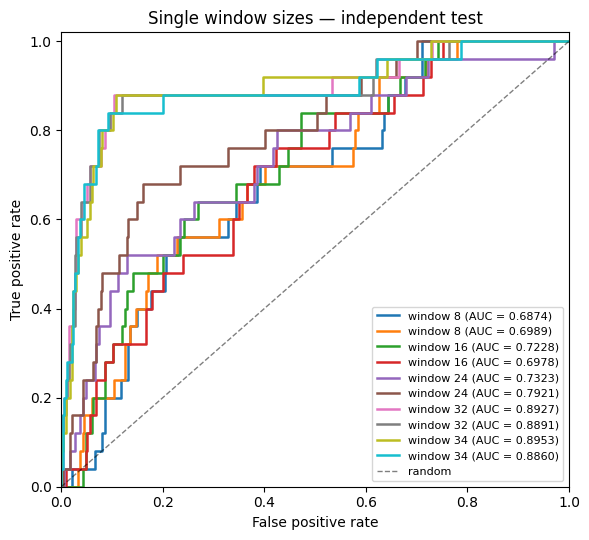

In [11]:
# Block 2 — Experiment A: single window sizes (paper Table 2)
cfgs = [dict(label=f"window {w}", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": [w], "filters": 512})
        for w in (8, 16, 24, 32, 34)]
runner.run_series("A_window", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("\nIndependent test")
display(results.fmt(results.table("A_window")))
print("5-fold cross-validation")
display(results.fmt(results.table("A_window", eval_split="cv")))
results.roc("A_window", title="Single window sizes — independent test");

[B_combo 1/5] [34]


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8742 | test AUC 0.8953
[B_combo 2/5] [34, 32]


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8502 | test AUC 0.8786
[B_combo 3/5] [34, 32, 24]


...

  seed 42: cv AUC 0.8597 | test AUC 0.8721
[B_combo 5/5] [34, 32, 24, 16, 8]


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8729 | test AUC 0.8863


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,[34],0.88,0.8862,0.8858,0.5227,0.8953,0.5032,0.5176,0.3667,0.8953,0.0
1,"[34, 32]",0.72,0.9371,0.9220,0.5375,0.8786,0.5128,0.5625,0.4615,0.8786,0.0
2,"[34, 32, 24]",0.80,0.9281,0.9192,0.5652,0.8810,0.4795,0.5797,0.4545,0.8810,0.0
3,"[34, 32, 24, 16]",0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
4,"[34, 32, 24, 16, 8]",0.88,0.8084,0.8134,0.4105,0.8863,0.5319,0.3964,0.2558,0.8863,0.0
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,[34],0.7353,0.9174,0.9045,0.5005,0.8742,0.4010,0.5226,0.4054,0.8742,0.0
1,"[34, 32]",0.5294,0.9557,0.9254,0.4628,0.8502,0.3683,0.5023,0.4779,0.8502,0.0
2,"[34, 32, 24]",0.5196,0.9294,0.9003,0.3805,0.8251,0.3187,0.4257,0.3605,0.8251,0.0
3,"[34, 32, 24, 16]",0.4608,0.9707,0.9344,0.4671,0.8597,0.4427,0.5000,0.5465,0.8597,0.0
4,"[34, 32, 24, 16, 8]",0.7647,0.8761,0.8682,0.4391,0.8729,0.3805,0.4522,0.3210,0.8729,0.0
5,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


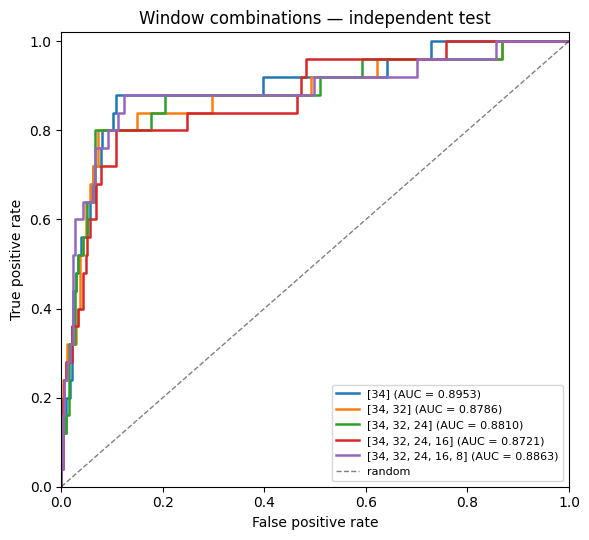

In [12]:
# Block 3 — Experiment B: window combinations (paper Table 3)
combos = [[34], [34, 32], [34, 32, 24], [34, 32, 24, 16], [34, 32, 24, 16, 8]]
cfgs = [dict(label=str(c), features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": c, "filters": 512}) for c in combos]
runner.run_series("B_combo", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("B_combo")))
display(results.fmt(results.table("B_combo", eval_split="cv")))
results.roc("B_combo", title="Window combinations — independent test");

[C_filters 1/5] 128 filters


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8857 | test AUC 0.8830
[C_filters 2/5] 256 filters


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8096 | test AUC 0.8669
[C_filters 3/5] 512 filters


...

/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8234 | test AUC 0.8552
[C_filters 5/5] 2048 filters


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.7661 | test AUC 0.8747


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std,conv_params
0,128 filters,0.76,0.9371,0.9248,0.5639,0.8830,0.5466,0.5846,0.4750,0.8830,0.0,13894144.0
1,256 filters,0.52,0.9521,0.9220,0.4410,0.8669,0.4786,0.4815,0.4483,0.8669,0.0,27788288.0
2,512 filters,0.76,0.9311,0.9192,0.5473,0.8892,0.5183,0.5672,0.4524,0.8892,0.0,55576576.0
3,1024 filters,0.40,0.9671,0.9276,0.3981,0.8552,0.4846,0.4348,0.4762,0.8552,0.0,111153152.0
4,2048 filters,0.28,0.9850,0.9359,0.3753,0.8747,0.4310,0.3784,0.5833,0.8747,0.0,222306304.0
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN,NaN


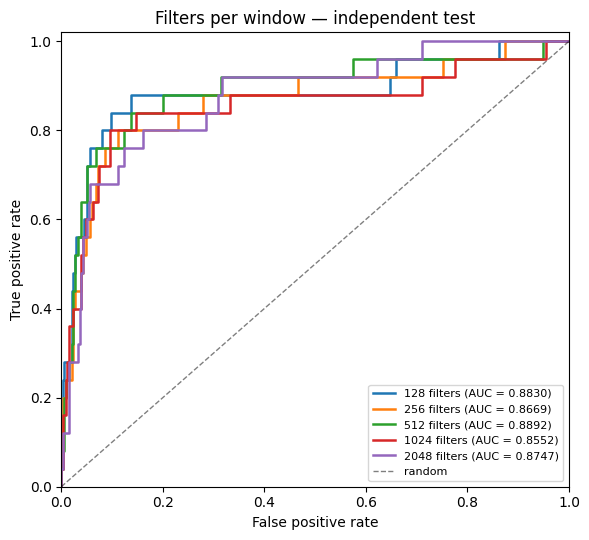

In [13]:
# Block 4 — Experiment C: filters per window (paper Table 4)
# conv_params is in the table on purpose: at 2048 filters the convolutions hold
# ~300M parameters for ~1.1k training peptides, which is the point of this sweep.
WINDOWS = [34, 32, 24, 16]
cfgs = [dict(label=f"{f} filters", features={"kind": "plm", "plm": PLM},
             model={"kind": "mcnn", "windows": WINDOWS, "filters": f,
                    "dropout": 0.5 if f >= 512 else 0.3},
             train_cfg={"batch_size": 16} if f >= 1024 else None)
        for f in (128, 256, 512, 1024, 2048)]
runner.run_series("C_filters", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("C_filters", extra_cols=("conv_params",))))
results.roc("C_filters", title="Filters per window — independent test");

[D_plm 1/3] ProtTrans


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8597 | test AUC 0.8721
[D_plm 2/3] ESM-2


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8865 | test AUC 0.8660
[D_plm 3/3] ESM-1b


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.9079 | test AUC 0.8766
Cross-validation (5 folds)


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,ProtTrans,0.4608,0.9707,0.9344,0.4671,0.8597,0.4427,0.5000,0.5465,0.8597,0.0
1,ESM-2,0.5098,0.9730,0.9400,0.5171,0.8865,0.4946,0.5474,0.5909,0.8865,0.0
2,ESM-1b,0.6569,0.9542,0.9331,0.5509,0.9079,0.4912,0.5826,0.5234,0.9079,0.0
3,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


Independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,ProtTrans,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
1,ESM-2,0.68,0.9581,0.9387,0.5782,0.8660,0.5589,0.6071,0.5484,0.8660,0.0
2,ESM-1b,0.56,0.9701,0.9415,0.5402,0.8766,0.5625,0.5714,0.5833,0.8766,0.0
3,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


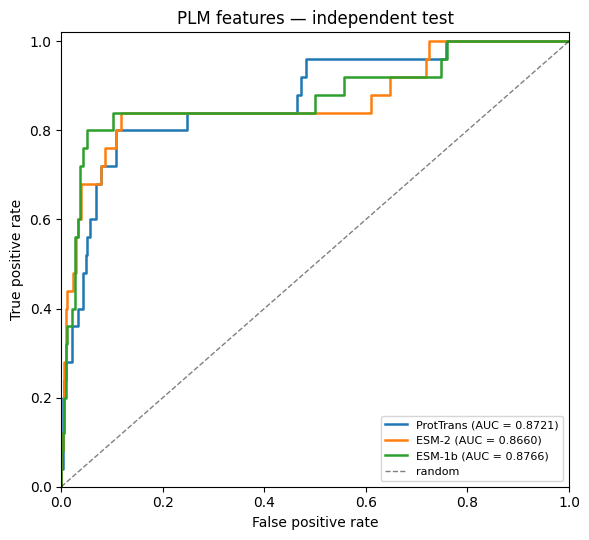

In [14]:
# Block 5 — Experiment D: pre-trained language model features (paper Table 5, Fig 4a)
BEST_WINDOWS, BEST_FILTERS = [34, 32, 24, 16], 512
cfgs = [dict(label=name, features={"kind": "plm", "plm": plm},
             model={"kind": "mcnn", "windows": BEST_WINDOWS, "filters": BEST_FILTERS})
        for plm, name in [("prott5", "ProtTrans"), ("esm2_650m", "ESM-2"), ("esm1b", "ESM-1b")]]
runner.run_series("D_plm", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Cross-validation (5 folds)")
display(results.fmt(results.table("D_plm", eval_split="cv")))
print("Independent test")
display(results.fmt(results.table("D_plm")))
results.roc("D_plm", title="PLM features — independent test");

[E_clf 1/4] KNN
  seed 42: cv AUC 0.5893 | test AUC 0.6185
[E_clf 2/4] RF
  seed 42: cv AUC 0.6628 | test AUC 0.7134
[E_clf 3/4] SVM
  seed 42: cv AUC 0.7418 | test AUC 0.6910
[E_clf 4/4] mCNN


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8597 | test AUC 0.8721


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,KNN,0.48,0.6946,0.6797,0.0955,0.6187,0.0963,0.1727,0.1053,0.6187,0.0
1,RF,0.12,0.9671,0.9081,0.1145,0.7134,0.1423,0.1538,0.2143,0.7134,0.0
2,SVM,0.44,0.7515,0.7298,0.1109,0.6910,0.1696,0.1849,0.1170,0.6910,0.0
3,mCNN,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
4,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


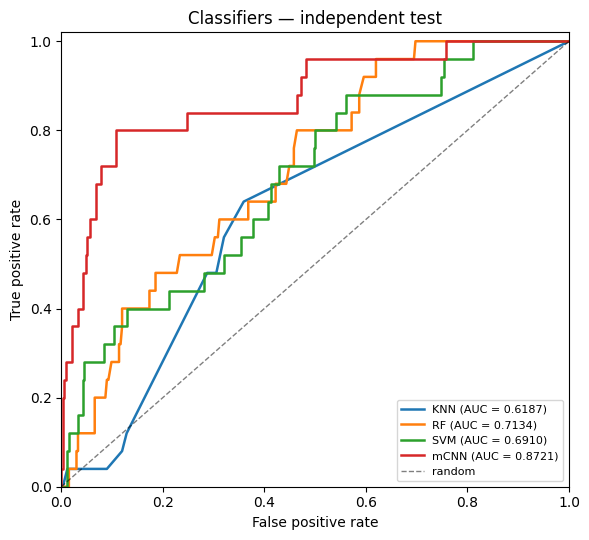

In [15]:
# Block 6 — Experiment E: classifiers (paper Table 6, Fig 4b)
# KNN / RF / SVM take the mean-pooled embedding; the mCNN keeps per-residue input.
cfgs = [dict(label=n.upper(), features={"kind": "plm_pooled", "plm": PLM},
             model={"kind": "sklearn", "name": n}) for n in ("knn", "rf", "svm")]
cfgs.append(dict(label="mCNN", features={"kind": "plm", "plm": PLM},
                 model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512}))
runner.run_series("E_clf", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("E_clf")))
results.roc("E_clf", title="Classifiers — independent test");

In [16]:
# Block 7 — Experiment F: MHC-I vs MHC-II (paper Table 7)
# No training: this re-scores the best stored run on two subsets of its own predictions.
rid = results.best_run("D_plm")
test = data.add_mhc_class(df[df["split"] == "test"])
subsets = {"Independent test": test["uid"],
           "MHC-I": test.loc[test["mhc"] == "I", "uid"],
           "MHC-II": test.loc[test["mhc"] == "II", "uid"]}
print("best run on CV:", rid)
display(results.fmt(results.breakdown(rid, subsets)))

best run on CV: D_plm__515017c4f3be


,Dataset,n,n_pos,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC
0,Independent test,359,25,0.5600,0.9701,0.9415,0.5402,0.8766,0.5625
1,MHC-I,21,11,0.3636,0.8000,0.5714,0.1809,0.5455,0.6066
2,MHC-II,338,14,0.7143,0.9753,0.9645,0.6120,0.9528,0.6782


[G_ladder 1/5] composition + LogReg
  seed 42: cv AUC 0.6603 | test AUC 0.6392
[G_ladder 2/5] one-hot CNN (w=8)


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.5886 | test AUC 0.6211
[G_ladder 3/5] one-hot mCNN


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.5874 | test AUC 0.6850
[G_ladder 4/5] pooled PLM + MLP


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.6863 | test AUC 0.6750
[G_ladder 5/5] PLM + mCNN


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8597 | test AUC 0.8721


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,composition + LogReg,0.48,0.7156,0.6992,0.1088,0.6392,0.1261,0.1818,0.1121,0.6392,0.0
1,one-hot CNN (w=8),0.12,0.9281,0.8719,0.0465,0.6211,0.1115,0.1154,0.1111,0.6211,0.0
2,one-hot mCNN,0.00,0.9970,0.9276,-0.0145,0.6850,0.1214,0.0000,0.0000,0.6850,0.0
3,pooled PLM + MLP,0.12,0.9671,0.9081,0.1145,0.6750,0.1559,0.1538,0.2143,0.6750,0.0
4,PLM + mCNN,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


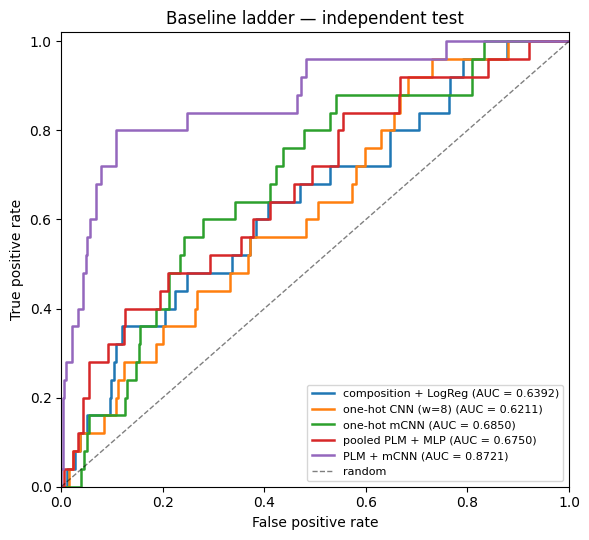

In [17]:
# Block 8 — Experiment G: the baseline ladder (CS535 E0-E3), plus a length-only control
# How much of the performance comes from composition alone, from order, from
# pretraining, and from local scanning on top of pretraining.
cfgs = [
    dict(label="length only (LogReg)", features={"kind": "length"},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="composition + LogReg", features={"kind": "aac"},
         model={"kind": "sklearn", "name": "logreg"}),
    dict(label="one-hot CNN (w=8)", features={"kind": "onehot"},
         model={"kind": "mcnn", "windows": [8], "filters": 256}),
    dict(label="one-hot mCNN", features={"kind": "onehot"},
         model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 256}),
    dict(label="pooled PLM + MLP", features={"kind": "plm_pooled", "plm": PLM},
         model={"kind": "mlp", "hidden": [256]}),
    dict(label="PLM + mCNN", features={"kind": "plm", "plm": PLM},
         model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512}),
]
runner.run_series("G_ladder", cfgs, df=df, seeds=SEEDS, force=FORCE)

display(results.fmt(results.table("G_ladder")))
results.roc("G_ladder", title="Baseline ladder — independent test");

In [18]:
# Block 9 — Experiment H: class weighting (CS535 E7)
# At ~1 positive per 13 negatives, this is what moves sensitivity against precision.
base = dict(features={"kind": "plm", "plm": PLM},
            model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512})
cfgs = [dict(label="weighted BCE", train_cfg={"class_weight": True}, **base),
        dict(label="unweighted BCE", train_cfg={"class_weight": False}, **base)]
runner.run_series("H_weight", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Tuned threshold (chosen on CV)")
display(results.fmt(results.table("H_weight")))
print("Fixed 0.5 threshold — note how differently 0.5 behaves between the two")
display(results.fmt(results.table("H_weight", thr_mode="fixed")))

[H_weight 1/2] weighted BCE


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8597 | test AUC 0.8721
[H_weight 2/2] unweighted BCE


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8326 | test AUC 0.8952
Tuned threshold (chosen on CV)


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
1,unweighted BCE,0.44,0.9820,0.9443,0.5058,0.8952,0.5351,0.5238,0.6471,0.8952,0.0
2,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


Fixed 0.5 threshold — note how differently 0.5 behaves between the two


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.24,0.994,0.9415,0.4035,0.8721,0.4774,0.3636,0.75,0.8721,0.0
1,unweighted BCE,0.04,0.997,0.9304,0.1266,0.8952,0.5351,0.0741,0.50,0.8952,0.0
2,all-negative baseline,0.00,1.000,0.9304,0.0000,0.5000,0.0696,0.0000,0.00,NaN,NaN


In [19]:
# Block 10 — Experiment I: similarity leakage (CS535 E8)
# Random folds let near-duplicate peptides sit on both sides of the split;
# grouped folds keep peptides that share an 8-mer together.
base = dict(features={"kind": "plm", "plm": PLM},
            model={"kind": "mcnn", "windows": [34, 32, 24, 16], "filters": 512})
cfgs = [dict(label="random folds", split_mode="stratified", **base),
        dict(label="similarity-controlled folds", split_mode="grouped", **base)]
runner.run_series("I_leak", cfgs, df=df, seeds=SEEDS, force=FORCE)

print("Cross-validation — the leakage shows up here, not on the test split")
display(results.fmt(results.table("I_leak", eval_split="cv")))
display(results.fmt(results.table("I_leak")))

g = data.kmer_groups(df)
print(f"\n{len(df)} peptides fall into {g.nunique()} shared-8-mer groups; "
      f"largest group has {g.value_counts().iloc[0]}")

[I_leak 1/2] random folds


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8597 | test AUC 0.8721
[I_leak 2/2] similarity-controlled folds


/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
/content/NeoAntigen/src/train.py:92: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.Gr

  seed 42: cv AUC 0.8241 | test AUC 0.8782
Cross-validation — the leakage shows up here, not on the test split


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.4608,0.9707,0.9344,0.4671,0.8597,0.4427,0.5000,0.5465,0.8597,0.0
1,similarity-controlled folds,0.3431,0.9872,0.9414,0.4543,0.8241,0.4218,0.4545,0.6731,0.8241,0.0
2,all-negative baseline,0.0000,1.0000,0.9289,0.0000,0.5000,0.0711,0.0000,0.0000,NaN,NaN


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
1,similarity-controlled folds,0.20,0.9910,0.9359,0.3294,0.8782,0.5043,0.3030,0.6250,0.8782,0.0
2,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN



1793 peptides fall into 1788 shared-8-mer groups; largest group has 2


--- Single window sizes (A_window) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,window 8,0.56,0.7186,0.7075,0.1546,0.6874,0.1232,0.2105,0.1296,0.6874,0.0000
1,window 8,0.16,0.9401,0.8858,0.1020,0.6989,0.1361,0.1633,0.1667,0.6939,0.0076
2,window 16,0.00,0.9940,0.9248,-0.0205,0.7228,0.1443,0.0000,0.0000,0.7228,0.0000
3,window 16,0.00,1.0000,0.9304,0.0000,0.6978,0.1389,0.0000,0.0000,0.6885,0.0102
4,window 24,0.36,0.9072,0.8691,0.2161,0.7323,0.1906,0.2769,0.2250,0.7323,0.0000
5,window 24,1.00,0.0000,0.0696,0.0000,0.7921,0.2369,0.1302,0.0696,0.7698,0.0240
6,window 32,0.36,0.9820,0.9387,0.4351,0.8927,0.5294,0.4500,0.6000,0.8917,0.0017
7,window 32,0.56,0.9641,0.9359,0.5147,0.8891,0.5313,0.5490,0.5385,0.8891,0.0000
8,window 34,0.88,0.8862,0.8858,0.5227,0.8953,0.5032,0.5176,0.3667,0.8953,0.0000
9,window 34,0.80,0.9281,0.9192,0.5652,0.8860,0.5196,0.5797,0.4545,0.8900,0.0114


--- Window combinations (B_combo) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,[34],0.88,0.8862,0.8858,0.5227,0.8953,0.5032,0.5176,0.3667,0.8953,0.0
1,"[34, 32]",0.72,0.9371,0.9220,0.5375,0.8786,0.5128,0.5625,0.4615,0.8786,0.0
2,"[34, 32, 24]",0.80,0.9281,0.9192,0.5652,0.8810,0.4795,0.5797,0.4545,0.8810,0.0
3,"[34, 32, 24, 16]",0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
4,"[34, 32, 24, 16, 8]",0.88,0.8084,0.8134,0.4105,0.8863,0.5319,0.3964,0.2558,0.8863,0.0
5,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


--- Filters per window (C_filters) — independent test


...

--- Class weighting (H_weight) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,weighted BCE,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
1,unweighted BCE,0.44,0.9820,0.9443,0.5058,0.8952,0.5351,0.5238,0.6471,0.8952,0.0
2,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN


--- Similarity leakage (I_leak) — independent test


,label,Sensitivity,Specificity,Accuracy,MCC,AUC,PR_AUC,F1,Precision,AUC_mean,AUC_std
0,random folds,0.48,0.9551,0.9220,0.4199,0.8721,0.4774,0.4615,0.4444,0.8721,0.0
1,similarity-controlled folds,0.20,0.9910,0.9359,0.3294,0.8782,0.5043,0.3030,0.6250,0.8782,0.0
2,all-negative baseline,0.00,1.0000,0.9304,0.0000,0.5000,0.0696,0.0000,0.0000,NaN,NaN



36 committed runs in /content/drive/MyDrive/s1156052/NeoAntigen/ckpt/results


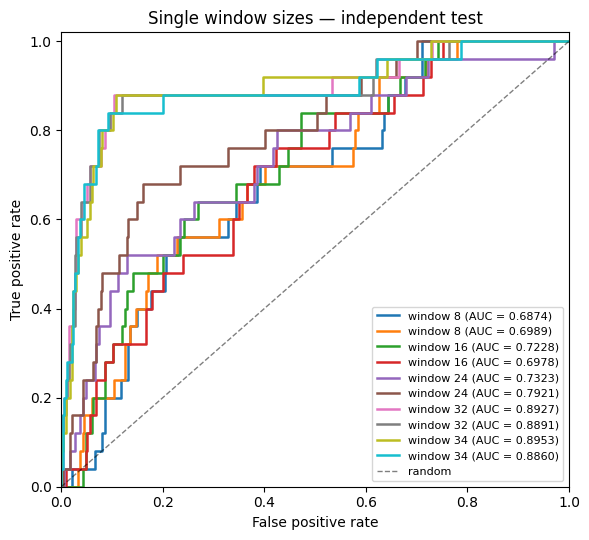

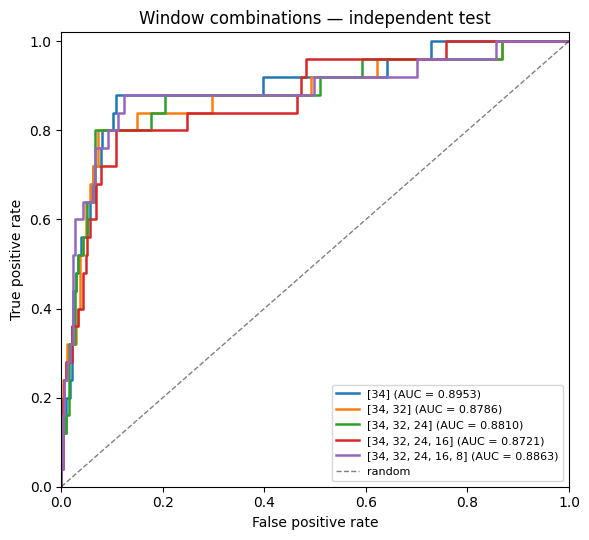

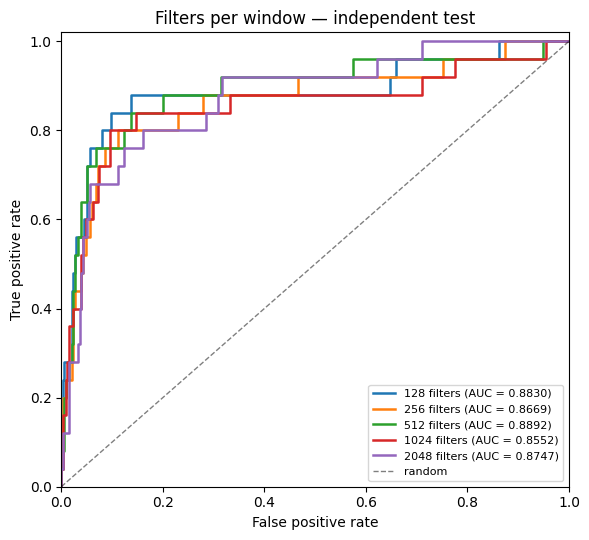

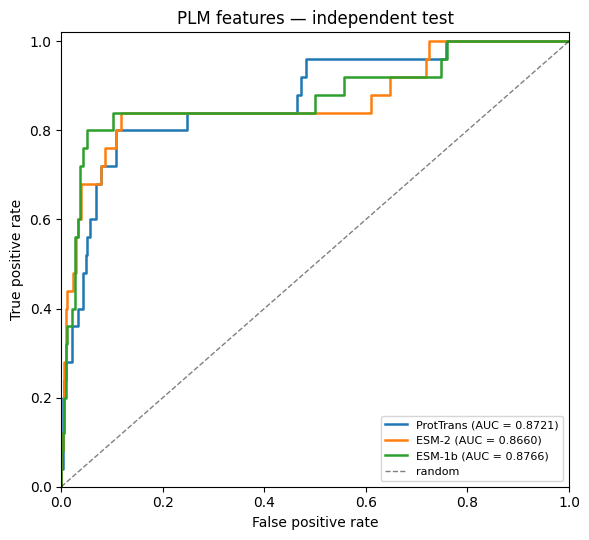

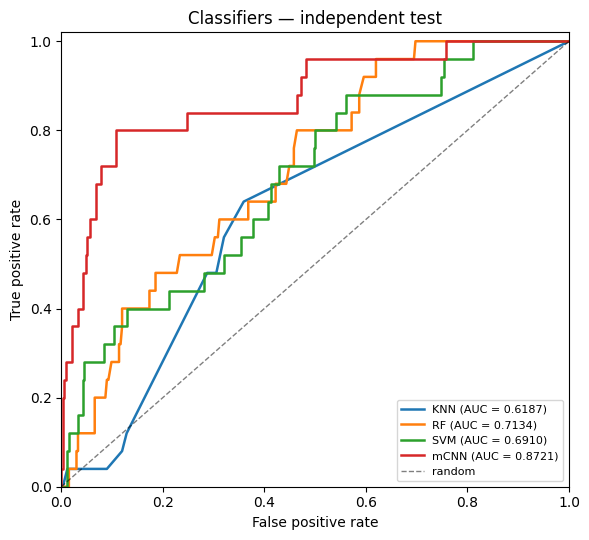

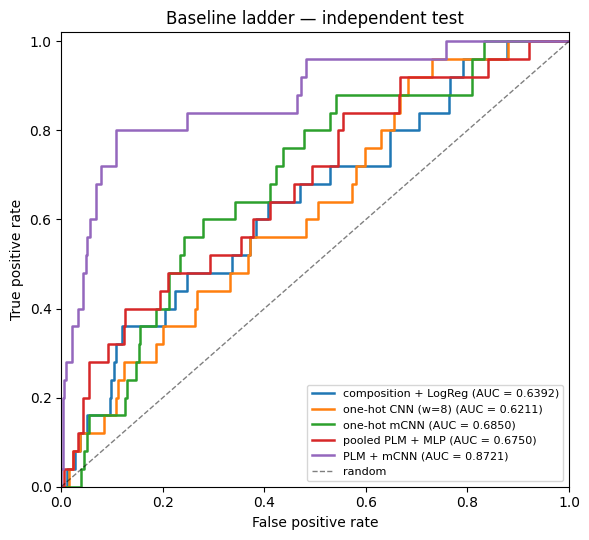

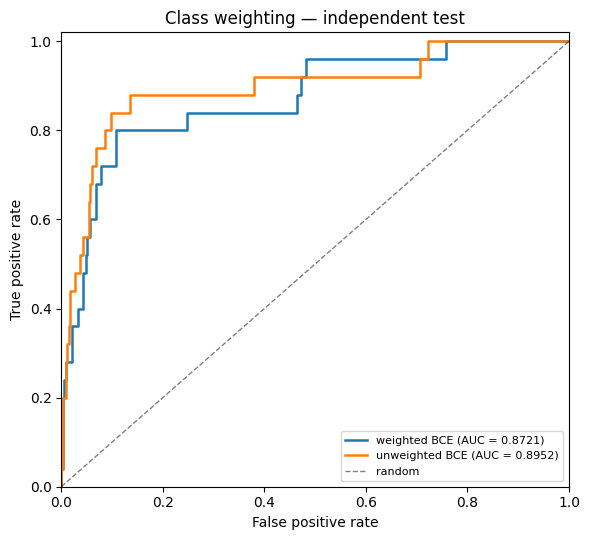

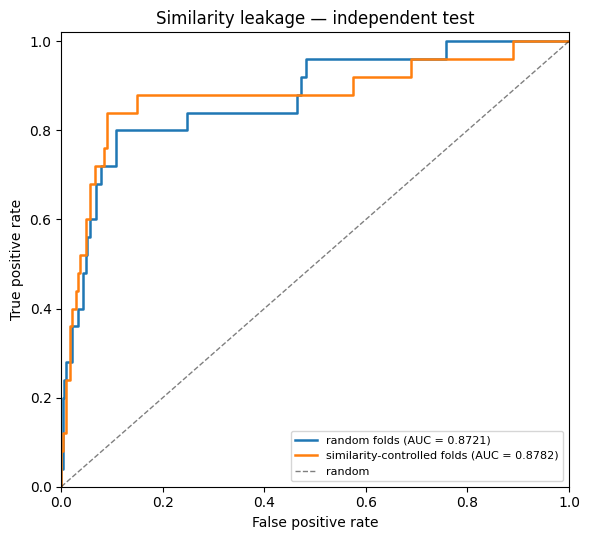

In [20]:
# Block 11 — report: every table and figure, rebuilt from the store. No training.
# This is what to run after a disconnect to see the whole state of the project.
TITLES = {"A_window": "Single window sizes", "B_combo": "Window combinations",
          "C_filters": "Filters per window", "D_plm": "PLM features",
          "E_clf": "Classifiers", "G_ladder": "Baseline ladder",
          "H_weight": "Class weighting", "I_leak": "Similarity leakage"}

for exp_id, title in TITLES.items():
    t = results.table(exp_id)
    if t.empty:
        print(f"--- {title}: not run yet\n")
        continue
    print(f"--- {title} ({exp_id}) — independent test")
    display(results.fmt(t))
    results.roc(exp_id, title=f"{title} — independent test")

runs = results.load_runs()
print(f"\n{len(runs)} committed runs in {config.RESULTS_DIR}")